### Project 08: HMMs using the Viterbi Algorithm
##### Background
* HMMs: a family of algorithms as a set of data structures
* predict hidden states based on observed stated
##### Goals of this project:
* tie together the conceptual aspects of all the other projects
* identify the most probable path through the hidden state transitions using the max probabilities
##### Tasks:
* create a data structure that can be extended down the line (future-proofing) utilizing object-oriented programming
* initialization --> recursion --> termination --> traceback
##### Complicated parts:
* proper documentation
* Setting up code structure
* understanding the steps of the formulas
##### Probabilities to keep track of:
* initial probability pointing to each state
* transition probability pointing from state to state
* emission probabilities (each emission for each state)
##### Notes from lecture:
* only need up to 3 nested for loops
* keep track of traceback similarly to smith-waterman
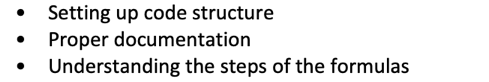

## The Viterbi Algorithm
Dynamic programming

$\pi_i$ = initial probabilities
* the chance that the first window is in each state
$a_ij$ = transition probabilities
* the chance that the next window is in state j when this window is in state i
$b_j$(k) = emission probabilities
* the chance that a window in state j shows symbol k

Each row of the transition table and each row of the emission table adds up to 1, because each row lists every possible outcome from one starting point

$\lambda$ = (A, B, $\pi$)
* the three sets together

Assumptions: (Markov propertiy)
* The next state depends only on the current state, not on any earlier window
* Each observation depends only on the state of its own window


### Formal Description by Durbin et al

#### initialization (i=0):
##### $v_0$(0) = 1, $v_k$(0) = 0, for k>0

#### Recursion (i=1...L):
##### $v_1$(i) = $e_1$($x_i$) * $max_k$($v_k$(i-1)$a_{k1}$)
##### $ptr_i$(1) = $argmax_k$($v_k$(i-1)$a_{k1}$)

#### Termination:
##### P(x, $\pi^*$) = $max_k$($v_k$(L)$a_{k0}$)
##### $\pi_L^*$ = $argmax_k$($v_k$(L)$a_{k0}$)

#### Traceback (i=L...1):
##### $\pi_{i-1}^*$ = $ptr_i$($\pi_i^*$)

* max: highest probability
* argmax: points to highest probability
* e: emission probability
* a: transition probability (move from one state to the next)
* k and L: current and next state
* i: the index for observation at point i
* x is the observation


## Points from Project08 Page

#### Key Features
* Optimal path finding: identifies the most probable sequence of hidden states.
* Dynamic programming: uses efficient tabulation to avoid redundant calculations.
* Log-space computation: prevents numerical underflow with long sequences by turning products into sums
* * In log space, multiplication becomes addition, and the max over previous states must likewise be converted into a sum of their log probabilities
* Traceback mechanism: reconstructs the optimal state path after computation.

#### Conceptual Questions to Consider
* "The most probable path" and "the most probable state at each position" sound alike. Are they the same thing? Can you construct a tiny example where the two disagree? (Hold on to this question; Project 09 will answer it for you.)
* The Viterbi recurrence has the same shape as the Smith–Waterman recurrence from Project 05. Line them up: what plays the role of the score, what plays the role of the gap, and what plays the role of traceback?
* How many probabilities must be considered to fill one column of the dynamic programming matrix?

#### Computational Questions to Consider
* Is log a monotonic function? If a>b, what can you say about $log_a$ and $log_b$? What, then, should happen to the max when you move to log space? Compare your answer with the last sentence above.
* What is log0? What does Python or numpy give you, and how will that value behave when you add it to other numbers or compare it with them?

#### Design Questions to Consider
* Every set of states, and the alphabet, must be derived from these dictionaries rather than hard-coded. Where in your design does that derivation happen, and what checks will you run on the inputs (do the rows sum to 1? are the keys consistent across dictionaries)?
* If you build an HMM class now, which attributes and methods will Projects 09 and 10 also need? Sketch the class so that it can grow without being rewritten.
* What should your Viterbi method return: the path only, the path and its probability, or more? In probability or log-probability?
* What is the hand-checkable answer for a one- or two-symbol observation sequence with the example parameters? Use it as your first test.
* What should happen if the observation contains a symbol that no state can emit?

Likely expansion algorithms onto this project based on "a Primer on HMMs"
* Forward
* Backward
* Forward-Backward
* Baum-Welch

In [19]:
# Initialization
# Set up a probability matrix using the initial probabilities and the first observation.
# Initialize a traceback matrix for path reconstruction.

In [20]:
# Recursion
# For each position and each possible state, calculate the maximum probability.
# Store both the probabilities and the traceback pointers.
# Apply transition and emission probabilities at each step.

In [21]:
# Termination
# Identify the final state with the highest probability.
# Trace back through the matrix to reconstruct the optimal path.

# Project09: Forward, Backward, and Forward-Backward Algorithms

### Background:
* Viterbi answers which single hidden path best explains the observations. Often that is the wrong question.
* We may instead want to know how likely the observations are under the model at all, summed over every path, or how confident we should be that position is in state given everything we observed.
* These are Rabiner's (1989) evaluation problem and the heart of posterior decoding.

### Objective:
* Demonstrate your understanding of hidden Markov models by implementing the Forward, Backward, and Forward–Backward algorithms for calculating sequence likelihoods and posterior probabilities.
* Extend the HMM code you began in Project 08.


Here we replace Viterbi's max with a sum
* Question: Why might an analyst prefer posterior probabilities over a single Viterbi path when annotating, say, exon boundaries?

### Quantities:
Forward probabilities, $\alpha_t$(i) = P($x_1$, ... $x_t$, $q_t$ = i), are the joint probability of having seen the first t observations and being in state i at time t.

The forward matrix is filled left to right, and summing its final column gives the total probability of the sequence, P(x).

Backward probabilities, $\beta_t$(i) = P($x_{t+1}$, ... $x_N$ | $q_t$ = i), are the probability of the remaining observations given that we are in state i at time i.

The backward matrix is initialized to 1 in its final column and filled right to left. Once it is complete, the same sequence probability can be recovered as P(x) = $\sum_{i}$($\beta_1$(i)

Posterior marginals, P($q_t$ = i | $x_1$, ... $x_N$), combine the two: the forward part accounts for everything before t, the backward part for everything after, and dividing by P(x) turns the joint quantity into a conditional one.



#### Key Features:
Joint probability calculation:
* the Forward algorithm computes P($x_1$, ... $x_t$, $q_t$ = i), the joint probability of the partial observation sequence and ending in state .

Conditional future probability:
* the Backward algorithm computes P($x_{t+1}$, ... $x_N$ | $q_t$ = i, the probability of future observations given the current state.

Posterior marginals:
* the Forward–Backward algorithm combines these to determine P($q_t$ = i | $x_1$, ... $x_N$), the probability of being in each state at each position given the entire observation sequence.

Dynamic programming: efficient recursion avoids exponential complexity.



Underflow:
* log(a+b) does not equal log(a) + log(b)

Use Scaling instead:
* Scaling normalizes each column of the forward (and backward) matrix as it is computed and keeps track of the scale factors (Rabiner, 1989).
* The log-sum-exp trick computes stably log$\sum_i$e<sup>${y_i}$ by factoring out the largest term.


#### Important Notes:
Yoon (2009) and Durbin et al. (1998) walk through the derivations; read at least one of them closely.

Forward and Backward compute the same quantity from opposite ends, so they must give identical results


#### Readme question
Does numpy or scipy already provide a stable log-sum-exp? Is using it acceptable here? Justify your answer in your README either way


#### Design Questions:
* Which parts of your Project 08 class can be reused unchanged, and which need refactoring so that max-based and sum-based recursions do not become two copies of the same loop?
* In what form will each method return its matrix: nested dictionaries keyed by state, or arrays with a fixed state order? How will callers know which row is which state?
* What hand-computable test will you use? With a two-symbol observation and the example parameters, you can compute P(x) by enumerating all four paths. Do it, and make it a test.
* Project 10 will call your Forward–Backward code many times inside a loop. What should it expose so that Baum–Welch can use it without recomputing anything?


##### Structure:
1. Forward algorithm
* Initialize with the initial probabilities and the first observation.
* Recursively calculate joint probabilities by summing over all possible previous states.
* Compute the total sequence probability by summing the final column.

2. Backward algorithm
* Initialize the final position with a value of 1 for all states.
* Recursively calculate conditional probabilities, working from the end to the beginning.
* Combine with the initial probabilities to get the sequence likelihood.

3. Forward–Backward algorithm
* Calculate both the forward and backward matrices.
* Combine them to compute the posterior marginal probability for each state at each position.
* Normalize to ensure a valid probability distribution.



In [22]:
"""
Example Data Structures

# Example observation sequence
obs = "GGCACTGAA"

# Example initial probabilities (probability of starting in each state)
init_probs = {
    "I": 0.2,
    "G": 0.8
}

# Example transition probabilities (probability of moving from one state to another)
trans_probs = {
    "I": {"I": 0.7, "G": 0.3},
    "G": {"I": 0.1, "G": 0.9}
}

# Example emission probabilities (probability of observing a symbol in a given state)
emit_probs = {
    "I": {"A": 0.1, "C": 0.4, "G": 0.4, "T": 0.1},
    "G": {"A": 0.3, "C": 0.2, "G": 0.2, "T": 0.3}
}

"""

'\nExample Data Structures\n\n# Example observation sequence\nobs = "GGCACTGAA"\n\n# Example initial probabilities (probability of starting in each state)\ninit_probs = {\n    "I": 0.2,\n    "G": 0.8\n}\n\n# Example transition probabilities (probability of moving from one state to another)\ntrans_probs = {\n    "I": {"I": 0.7, "G": 0.3},\n    "G": {"I": 0.1, "G": 0.9}\n}\n\n# Example emission probabilities (probability of observing a symbol in a given state)\nemit_probs = {\n    "I": {"A": 0.1, "C": 0.4, "G": 0.4, "T": 0.1},\n    "G": {"A": 0.3, "C": 0.2, "G": 0.2, "T": 0.3}\n}\n\n'

In [23]:

import numpy as np

class HiddenMarkovModel:
    """
    Main class for the implementation of different algorithms used by HMMs

    This class will be used to calculate probabilities of hidden states based on observed states using algorithms that include:
        The Viterbi Algorithm
        The Forward Algorithm
        The Backward Algorithm
        The Forward-Backward Algorithm

    """
    def __init__(self, states, observation_symbols,
                 initial_probability,
                 transition_probability,
                 emission_probability):
        """
        Initialize objects used in HMM
        """

        self.states = states
        self.observation_symbols = observation_symbols
        self.observation_sequence = None # Don't know the sequence yet so set it to None

        # Probabilities
        self.initial_probability = initial_probability
        self.transition_probability = transition_probability
        self.emission_probability = emission_probability

        # Log probabilities initialized in convert_to_log()
        self.log_initial_probability = None
        self.log_transition_probability = None
        self.log_emission_probability = None

        # initialization matrices
        self.viterbi_matrix = None
        self.viterbi_traceback_matrix = None

        # Termination attributes
        self.best_final_score = None
        self.best_final_state = None
        self.last_observation = None




    def convert_to_log(self):
        """
        Helper function to convert probabilities to log to avoid underflow

        Pseudocode:
        Convert each probability array to log probability array; store as new attribute
        """

        self.log_initial_probability = np.log(self.initial_probability)
        self.log_transition_probability = np.log(self.transition_probability)
        self.log_emission_probability = np.log(self.emission_probability)



    def initialization_viterbi(self):
        """
        Initialize stuff for probabilities and traceback matrix

        # Set up a probability matrix using the initial probabilities and the first observation.
        # Initialize a traceback matrix for path reconstruction.
        # No transition probs here

        Pseudocode:
        Get the number of hidden states and the length of the observation sequence
            # Rows = number of hidden states
            # Columns = length of observation sequence
        Initialize dimensions of both probability and traceback matrices
            # viterbi_matrix = np.zeros((rows, columns))
            # viterbi_traceback_matrix = np.zeros((rows, columns), dtype=int)
        Initialize the first column of the traceback with a character because there aren't previous states to the first state
        Getting the first observation and its emission probability
            # Establish the first observation at index 0 for observation sequence
            # Create a symbol index to get the probability for the symbol at observation sequence index 0
            # Get the emission probabilities for all rows in column 1 at symbol index for that position in sequence
        Calculation for first column of probabilities
            # initial probability from symbol, index + the first emission probability (remember we are in log, so its addition)
        Store in first column of the probability matrix


        """

        # Establish array dimensions
        rows = len(self.states)
        columns = len(self.observation_sequence)

        # create the shape of the arrays
        self.viterbi_matrix = np.zeros((rows, columns))
        self.viterbi_traceback_matrix = np.zeros((rows, columns), dtype=int)
        # first col of traceback has sentinel character
        self.viterbi_traceback_matrix[:,0] = -1

        first_obs = self.observation_sequence[0] # First: get the symbol at index 0 in the sequence
        symbol_index = self.observation_symbols.index(first_obs) # Next get the index of that symbol from our alphabet
        first_emit = self.log_emission_probability[:, symbol_index] # Then get the emission probabilities associated with that symbol

        # add the log probabilities to get the first column
        first_col = symbol_index + first_emit

        # insert into probability matrix
        self.viterbi_matrix[:,0] = first_col


    def calculate_viterbi_score(self):
        """
        Function to calculate the maximum probabilities of each using the Viterbi algorithm.

        # max is for probability matrix
        # argmax is for traceback matrix

        Pseudocode:
        Iterate through each observation
        iterate through each possible hidden state at that position
        calculate probabilities for each hidden state from previous state
        find the max
        Add that to emission probability
        store that
        store the previous state that produced it for the traceback
        """

        # for each index in the observation sequence starting after the initial
        for i in range(1, len(self.observation_sequence)):

            # for our current states index:
            for current_state in range(len(self.states)):

                # Create an array of all candidate scores
                # Get the argmax from the best previous index
                # Get the best previous state from the model based on our current state
                    # here we get the max of our matrix index - 1 (prev index) at previous state plus the transition probability for the prev state at current state
                previous_scores = self.viterbi_matrix[:, i-1] + self.log_transition_probability[:, current_state]

                best_previous_state = np.argmax(previous_scores)
                max_previous_probability = np.max(previous_scores)

                # Append these into our arrays
                # at index i in our current state, add the maximum prev prob and the emission prob for current state at index i of sequence
                self.viterbi_matrix[current_state, i] = (max_previous_probability +self.log_emission_probability[current_state][self.observation_symbols.index(self.observation_sequence[i])])

                # Add the best previous into traceback while at current position at index i
                self.viterbi_traceback_matrix[current_state, i] = best_previous_state


    def termination_viterbi(self):
        """
        Function to determine the maximums

        Pseudocode:
        Determine the last index of the observation sequence
        Determine the best final state
        Determine the best final probability

        """

        # Take the last index from the sequence
        self.last_observation = len(self.observation_sequence)-1
        # Get the maximum final state
        self.best_final_state = np.argmax(self.viterbi_matrix[:, self.last_observation])
        # Get the best path from the last observation and maximum final state
        self.best_final_score = self.viterbi_matrix[self.best_final_state][self.last_observation]


    def traceback_viterbi(self):
        """
        Set up traceback path for Viterbi algorithm for most-probable paths.

        Initialize with the best final state
        Set current state equal to that
        iterate backwards through the observations
        look at previous state based on current state and position
        update current state to previous state
        add previous state into path
        iterate until start
        reverse the final order


        Logic:
        Iterate backwards from the maximum final state probability. For each iteration, we want to find the maximum previous state based on our current state and position. We use the already-filled out traceback matrix and start at the best final at index i and move back. We append that previous state into the best path.

        """

        best_path = [self.best_final_state]
        current_state = self.best_final_state

        for i in range(self.last_observation, 0, -1):
            previous_state = self.viterbi_traceback_matrix[current_state, i]


            best_path.append(previous_state)
            current_state = previous_state

        best_path = [self.states[i] for i in reversed(best_path)]
        return best_path



    def viterbi(self):
        """
        Function similar to Smith-Waterman in which we call calculate_viterbi_score and traceback_viterbi to find the optimal path.

        """
        self.convert_to_log()
        self.initialization_viterbi()
        self.calculate_viterbi_score()
        self.termination_viterbi()
        best_path = self.traceback_viterbi()

        return best_path


    # Eventually also have calculate_forward_score, calculate_backward_score, calculate_forward_backward_score


In [25]:


# Example initial probabilities (probability of starting in each state)
states = ["Genome", "Island"]
observations = ["A", "C", "G", "T"]
init_probs = [0.2, 0.8]
# "Island": 0.2, "Genome": 0.8


# Example transition probabilities (probability of moving from one state to another)
trans_probs = np.array([
    [0.7, 0.3],
    [0.1, 0.9]])

# "Island": {"I": 0.7, "G": 0.3}, "Genome": {"I": 0.1, "G": 0.9}
# Example emission probabilities (probability of observing a symbol in a given state)
emit_probs = np.array([
    [0.1, 0.4, 0.4, 0.1],
    [0.3, 0.2, 0.2, 0.3]
])

# "Island": {"A": 0.1, "C": 0.4, "G": 0.4, "T": 0.1},
# "Genome": {"A": 0.3, "C": 0.2, "G": 0.2, "T": 0.3}


# Example observation sequence
obs_seq = "GGCACTGAA"



In [29]:
hmm = HiddenMarkovModel(
    states=states,
    observation_symbols=observations,
    initial_probability=init_probs,
    transition_probability=trans_probs,
    emission_probability=emit_probs
)
hmm.observation_sequence = obs_seq
result = hmm.viterbi()
print(result)


['Genome', 'Genome', 'Genome', 'Island', 'Island', 'Island', 'Island', 'Island', 'Island']


# Core Limitation
This program can only accept Numpy arrays, not dictionaries.

The easiest way to overcome this would be to do an if else statement where:
* if probability is dict, convert to np.array;
* else probability is an array

In [27]:
# Example for project 9
"""
# Example observation sequence
obs = "ATGCAA"

# Example initial probabilities (probability of starting in each state: E := Exon, I := Intron)
init_probs = {
    "E": 0.6,
    "I": 0.4
}

# Example transition probabilities (probability of moving from one state to another)
trans_probs = {
    "E": {"E": 0.8, "I": 0.2},
    "I": {"E": 0.3, "I": 0.7}
}

# Example emission probabilities (probability of observing a symbol in a given state)
emit_probs = {
    "E": {"A": 0.3, "C": 0.2, "G": 0.2, "T": 0.3},
    "I": {"A": 0.1, "C": 0.4, "G": 0.4, "T": 0.1}
}
"""

'\n# Example observation sequence\nobs = "ATGCAA"\n\n# Example initial probabilities (probability of starting in each state: E := Exon, I := Intron)\ninit_probs = {\n    "E": 0.6,\n    "I": 0.4\n}\n\n# Example transition probabilities (probability of moving from one state to another)\ntrans_probs = {\n    "E": {"E": 0.8, "I": 0.2},\n    "I": {"E": 0.3, "I": 0.7}\n}\n\n# Example emission probabilities (probability of observing a symbol in a given state)\nemit_probs = {\n    "E": {"A": 0.3, "C": 0.2, "G": 0.2, "T": 0.3},\n    "I": {"A": 0.1, "C": 0.4, "G": 0.4, "T": 0.1}\n}\n'